<a href="https://colab.research.google.com/github/ankit9508220322/All_folder/blob/main/iskill_project_data_Analytic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data = pd.read_csv('/content/Zomato data.csv')
data

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet
...,...,...,...,...,...,...,...
143,Melting Melodies,No,No,3.3/5,0,100,Dining
144,New Indraprasta,No,No,3.3/5,0,150,Dining
145,Anna Kuteera,Yes,No,4.0/5,771,450,Dining
146,Darbar,No,No,3.0/5,98,800,Dining


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   name                         148 non-null    object
 1   online_order                 148 non-null    object
 2   book_table                   148 non-null    object
 3   rate                         148 non-null    object
 4   votes                        148 non-null    int64 
 5   approx_cost(for two people)  148 non-null    int64 
 6   listed_in(type)              148 non-null    object
dtypes: int64(2), object(5)
memory usage: 8.2+ KB


In [ ]:
data.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
143,False
144,False
145,False
146,False


In [ ]:
data.isnull().sum()

,0
name,0
online_order,0
book_table,0
rate,0
votes,0
approx_cost(for two people),0
listed_in(type),0


In [ ]:
data.describe()

,votes,approx_cost(for two people)
count,148.000000,148.000000
mean,264.810811,418.243243
std,653.676951,223.085098
min,0.000000,100.000000
25%,6.750000,200.000000
50%,43.500000,400.000000
75%,221.750000,600.000000
max,4884.000000,950.000000


In [ ]:
data.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [ ]:
data.tail()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
143,Melting Melodies,No,No,3.3/5,0,100,Dining
144,New Indraprasta,No,No,3.3/5,0,150,Dining
145,Anna Kuteera,Yes,No,4.0/5,771,450,Dining
146,Darbar,No,No,3.0/5,98,800,Dining
147,Vijayalakshmi,Yes,No,3.9/5,47,200,Dining


In [ ]:
data.sample()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
143,Melting Melodies,No,No,3.3/5,0,100,Dining


In [ ]:
def hendalrate(value):
    if pd.isna(value):
        return None

    value = str(value).split('/')
    value = value[0]
    return float(value)

data['rate'] = data['rate'].apply(hendalrate)
data['rate']

,rate
0,4.1
1,4.1
2,3.8
3,3.7
4,3.8
...,...
143,3.3
144,3.3
145,4.0
146,3.0


In [ ]:
# convert data type reating
# data['rate']=data['rate'].str.replace('/', '', regex=False)
# data['rate']

In [ ]:
data.head(2)

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet


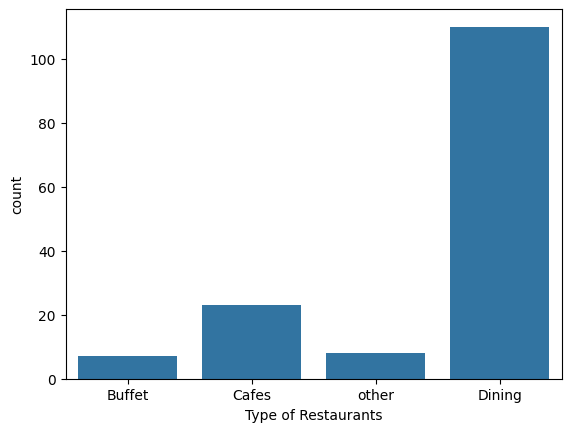

In [ ]:
# typr of resturent
sns.countplot(x=data['listed_in(type)'],y=data['votes'])
plt.xlabel('Type of Restaurants')
plt.show()

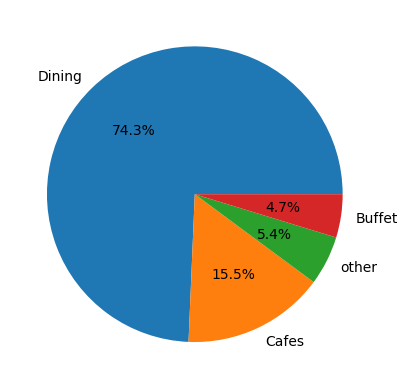

In [ ]:
data['listed_in(type)'].value_counts().plot(kind='pie',autopct='%1.1f%%')
plt.ylabel('')
plt.show()

In [ ]:
data.head(1)

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet


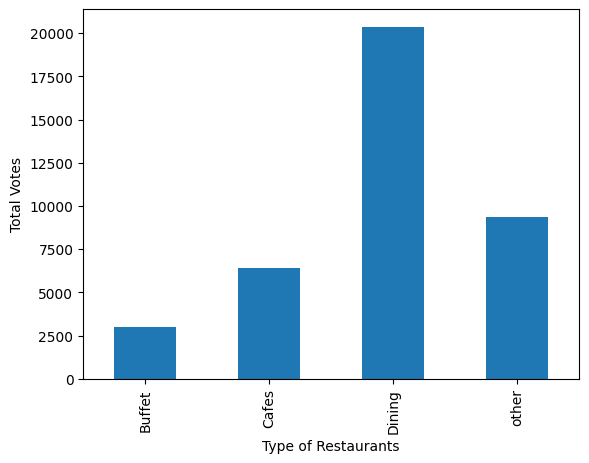

In [ ]:
votes = data.groupby('listed_in(type)')['votes'].sum()

votes.plot(kind='bar')

plt.xlabel('Type of Restaurants')
plt.ylabel('Total Votes')
plt.show()

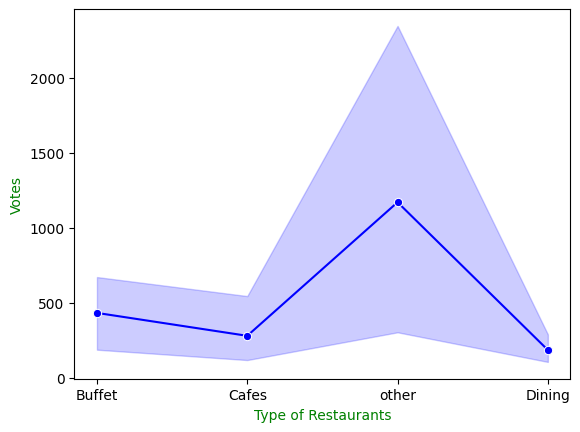

In [ ]:
sns.lineplot(x=data['listed_in(type)'], y=data['votes'],color='blue',marker = 'o')
plt.xlabel('Type of Restaurants',color='green')
plt.ylabel('Votes',color='green')
plt.show()

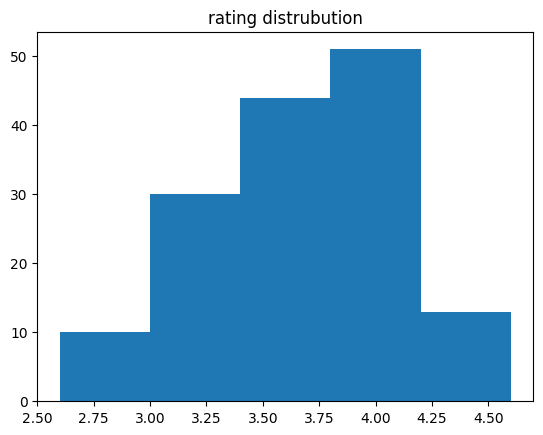

In [ ]:
plt.hist(data['rate'],bins=5)
plt.title("rating distrubution")
plt.show()

**conclusion- The majority resturent received rating from 3.5 to 4**

<Axes: xlabel='approx_cost(for two people)', ylabel='count'>

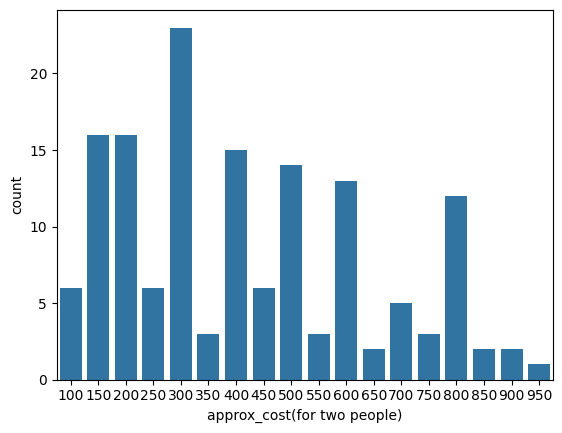

In [ ]:
result = data['approx_cost(for two people)']
sns.countplot(x=result)

# **conclusion the majority of couples prefect resturent with an approx cost 300 repes**

<Axes: xlabel='online_order', ylabel='rate'>

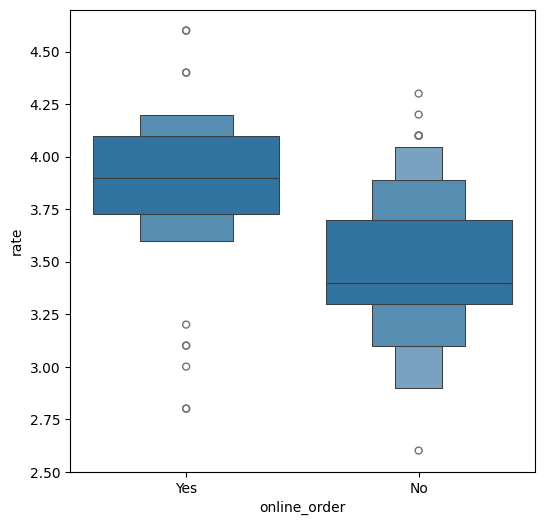

In [ ]:
plt .figure(figsize=(6,6))
sns.boxenplot(x='online_order',y ='rate',data = data)

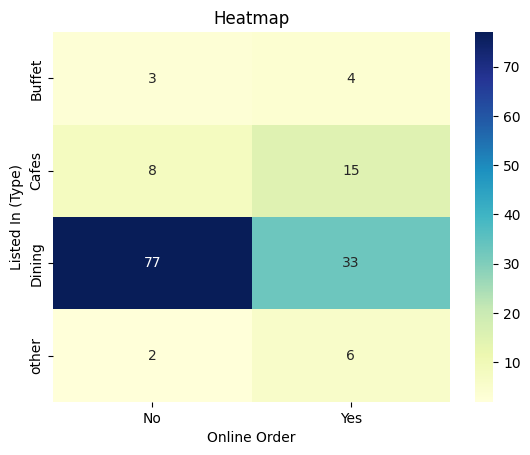

In [ ]:
pivot_table = data.pivot_table(
    index='listed_in(type)',
    columns='online_order',
    aggfunc='size',
    fill_value=0
)

sns.heatmap(
    pivot_table,
    annot=True,
    cmap='YlGnBu',
    fmt='d'
)

plt.title("Heatmap")
plt.xlabel("Online Order")
plt.ylabel("Listed In (Type)")
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')